In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from textblob import TextBlob
from wordcloud import WordCloud
import nltk


In [2]:
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

In [3]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [4]:
file_path = '/content/drive/MyDrive/Data/chatgpt_reviews.csv'
df = pd.read_csv(file_path)

In [5]:
print(f"Dataset Shape: {df.shape}")
display(df.head())
df.info()

Dataset Shape: (196727, 4)


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB


In [7]:
#Step 2: Data Preparation & Cleaning

In [8]:
# 1. Standardize column names to snake_case
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

In [9]:
# 2. Check and remove duplicate review_ids (3,573 duplicates exist in the raw file)
print("Duplicate review_ids found:", df['review_id'].duplicated().sum())
df = df.drop_duplicates(subset=['review_id']).copy()

Duplicate review_ids found: 3573


In [10]:
# 3. Handle missing values in 'review' (6 NaN entries)
print("Missing reviews before cleaning:", df['review'].isnull().sum())
df['review'] = df['review'].fillna('').astype(str)

Missing reviews before cleaning: 6


In [11]:
# 4. Enforce numeric ratings and datetime formatting
df['ratings'] = pd.to_numeric(df['ratings'], errors='coerce')
df['review_date'] = pd.to_datetime(df['review_date'], errors='coerce')

In [12]:
# 5. Feature engineering: extract year-month and review word count for EDA
df['year_month'] = df['review_date'].dt.to_period('M').astype(str)
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

print(f"Cleaned Dataset Shape: {df.shape}")
display(df.isnull().sum())

Cleaned Dataset Shape: (193154, 6)


,0
review_id,0
review,0
ratings,0
review_date,0
year_month,0
word_count,0


In [13]:
#Step 3: Exploratory Data Analysis (EDA)

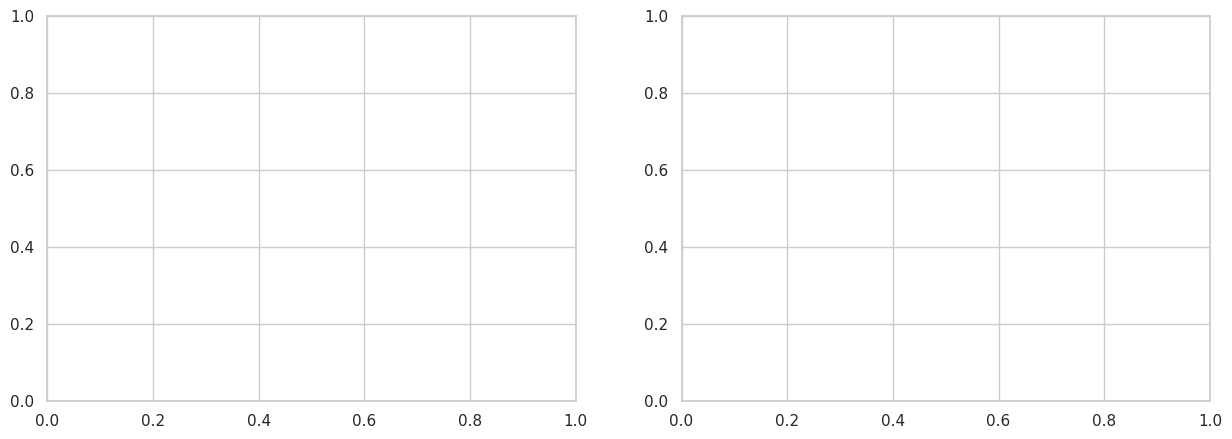

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

In [15]:
# Chart 1: Star Rating Distribution
rating_counts = df['ratings'].value_counts().sort_index()
sns.barplot(x=rating_counts.index, y=rating_counts.values, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of User Star Ratings (1–5)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Number of Reviews')
for idx, val in enumerate(rating_counts.values):
    axes[0].text(idx, val + 2000, f"{val:,}\n({val/len(df)*100:.1f}%)", ha='center', fontsize=9)
axes[0].set_ylim(0, max(rating_counts.values) * 1.18)

/tmp/ipykernel_1141/2127654776.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts.index, y=rating_counts.values, ax=axes[0], palette='viridis')


(0.0, 174416.97999999998)

In [16]:
# Chart 2: Monthly Review Volume Trend
monthly_counts = df.groupby('year_month').size()
monthly_counts.plot(kind='line', marker='o', ax=axes[1], color='#2980b9', linewidth=2)
axes[1].set_title('Monthly Review Volume Over Time', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Review Count')
axes[1].tick_params(axis='x', rotation=45)

In [17]:
plt.tight_layout()
plt.show()

print(df[['ratings', 'word_count']].describe().round(2))

<Figure size 1000x500 with 0 Axes>

         ratings  word_count
count  193154.00   193154.00
mean        4.51        8.69
std         1.08       13.44
min         1.00        0.00
25%         5.00        2.00
50%         5.00        4.00
75%         5.00        9.00
max         5.00      134.00


In [19]:
#Step 4: Sentiment Analysis (Polarity & Subjectivity)

In [20]:
# Function to compute polarity and subjectivity efficiently
def analyze_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity, blob.sentiment.subjectivity

# Run across all 193,154 reviews (~15-20 seconds in Colab)
sentiments = [analyze_sentiment(text) for text in df['review']]
df['polarity'] = [s[0] for s in sentiments]
df['subjectivity'] = [s[1] for s in sentiments]

# Categorize polarity into Positive, Neutral, and Negative
def classify_polarity(score):
    if score > 0.05:
        return 'Positive'
    elif score < -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment_category'] = df['polarity'].apply(classify_polarity)

# Summary table comparing Star Ratings vs Mean NLP Polarity & Subjectivity
summary_by_rating = df.groupby('ratings')[['polarity', 'subjectivity']].agg(['mean', 'median']).round(3)
display(summary_by_rating)

print("\nSentiment Category Breakdown:")
print(df['sentiment_category'].value_counts())
print((df['sentiment_category'].value_counts(normalize=True) * 100).round(2))

polarity        subjectivity       
            mean median         mean median
ratings                                    
1          0.013  0.000        0.381  0.400
2          0.161  0.000        0.427  0.500
3          0.308  0.267        0.467  0.533
4          0.426  0.445        0.518  0.600
5          0.500  0.540        0.532  0.600


Sentiment Category Breakdown:
sentiment_category
Positive    146360
Neutral      39764
Negative      7030
Name: count, dtype: int64
sentiment_category
Positive    75.77
Neutral     20.59
Negative     3.64
Name: proportion, dtype: float64


In [21]:
#Step 5: Text Analysis & Keyword Extraction (Positive vs. Critical)

In [22]:
# Combine NLTK stopwords with domain-specific filler words
stop_words = set(stopwords.words('english')).union({
    'app', 'chatgpt', 'ai', 'gpt', 'chat', 'use', 'using', 'used',
    'really', 'also', 'would', 'get', 'like', 'one', 'even', 'much'
})

def get_top_keywords(text_series, n=15):
    words = []
    for text in text_series:
        # Extract alphabetic words with 3+ characters
        tokens = re.findall(r'\b[a-z]{3,}\b', text.lower())
        words.extend([w for w in tokens if w not in stop_words])
    return Counter(words).most_common(n)

# Filter positive (4-5 stars) and negative (1-2 stars) reviews
pos_reviews = df[df['ratings'] >= 4]['review']
neg_reviews = df[df['ratings'] <= 2]['review']

top_pos_words = get_top_keywords(pos_reviews, 15)
top_neg_words = get_top_keywords(neg_reviews, 15)

print("Top 15 Positive Keywords (4–5 Stars):", top_pos_words)
print("Top 15 Critical Keywords (1–2 Stars):", top_neg_words)

Top 15 Positive Keywords (4–5 Stars): [('good', 35283), ('best', 17629), ('nice', 12798), ('great', 11164), ('helpful', 11022), ('amazing', 8412), ('love', 8323), ('useful', 7199), ('excellent', 6024), ('awesome', 4969), ('ever', 3880), ('help', 3831), ('helps', 3400), ('work', 3259), ('information', 3214)]
Top 15 Critical Keywords (1–2 Stars): [('good', 1669), ('time', 903), ('working', 839), ('error', 833), ('work', 826), ('please', 825), ('login', 749), ('bad', 728), ('answer', 685), ('wrong', 644), ('information', 591), ('give', 589), ('try', 578), ('phone', 569), ('google', 565)]


In [23]:
#Step 6: Comprehensive Visualizations (Charts & Word Cloud)

/tmp/ipykernel_1141/3717405361.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sent_counts.index, y=sent_counts.values, ax=axes[0, 0], palette=['#2ecc71', '#95a5a6', '#e74c3c'])
/tmp/ipykernel_1141/3717405361.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='ratings', y='polarity', data=df, ax=axes[0, 1], palette='viridis')
/tmp/ipykernel_1141/3717405361.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Keyword', data=pos_df, ax=axes[1, 1], palette='crest')


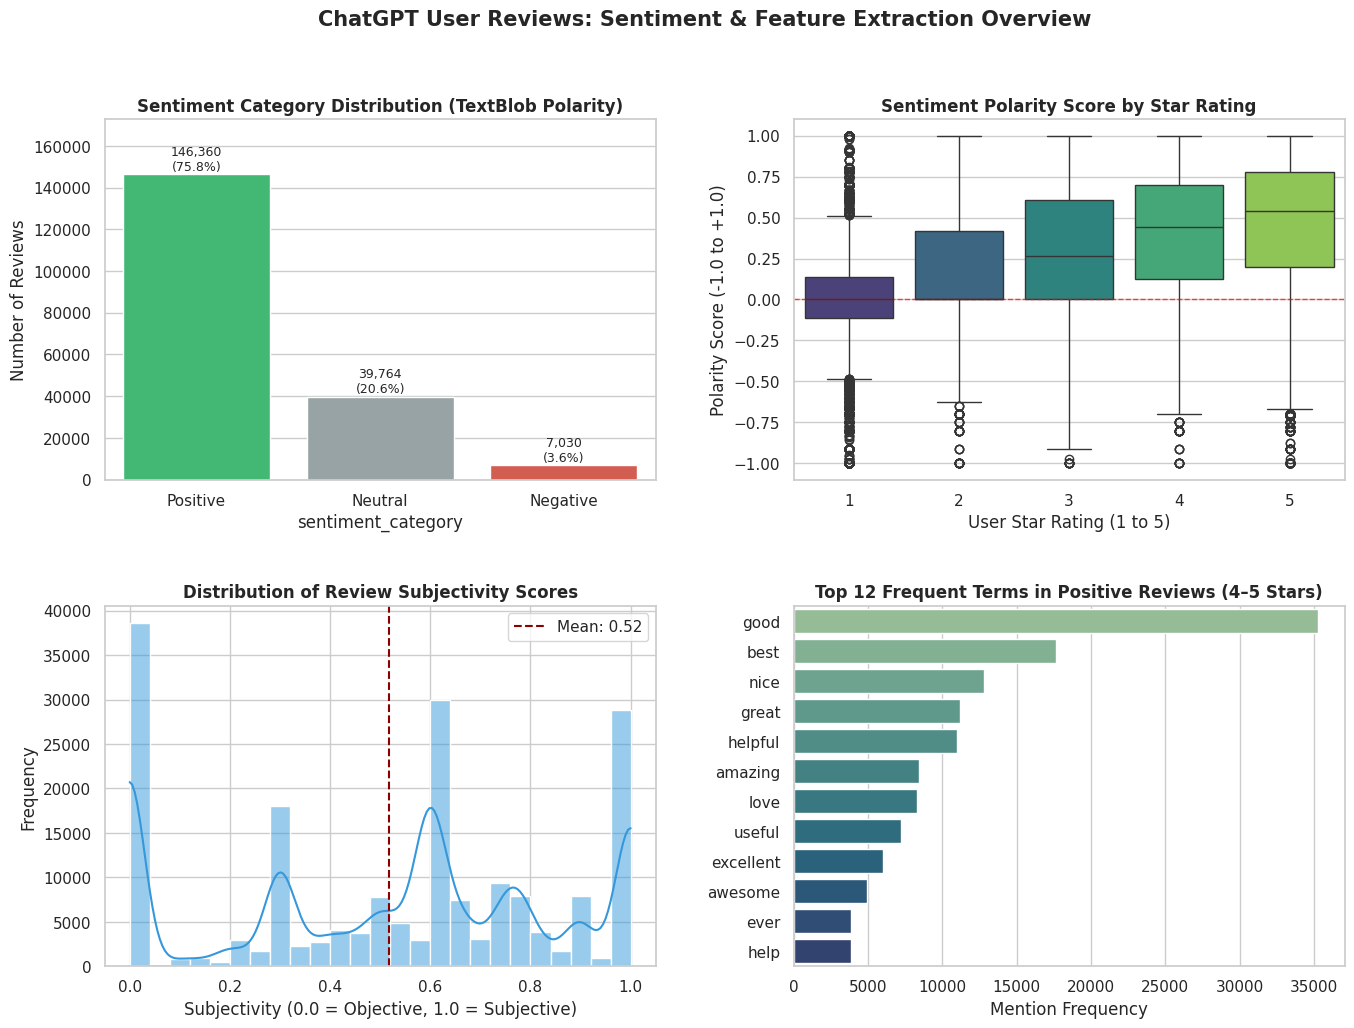

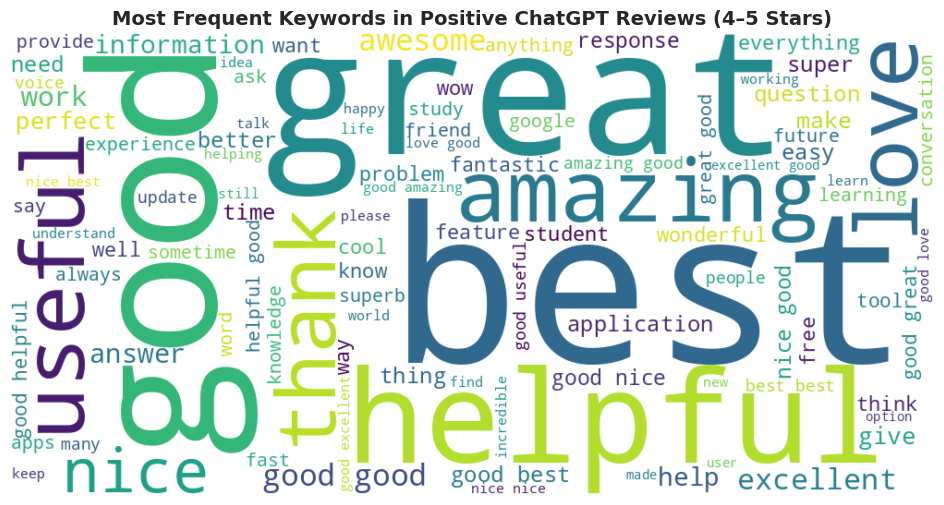

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Sentiment Category Distribution
sent_counts = df['sentiment_category'].value_counts()
sns.barplot(x=sent_counts.index, y=sent_counts.values, ax=axes[0, 0], palette=['#2ecc71', '#95a5a6', '#e74c3c'])
axes[0, 0].set_title('Sentiment Category Distribution (TextBlob Polarity)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Number of Reviews')
for i, v in enumerate(sent_counts.values):
    axes[0, 0].text(i, v + 2000, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontsize=9)
axes[0, 0].set_ylim(0, max(sent_counts.values) * 1.18)

# 2. Polarity vs. User Star Ratings (Boxplot)
sns.boxplot(x='ratings', y='polarity', data=df, ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Sentiment Polarity Score by Star Rating', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('User Star Rating (1 to 5)')
axes[0, 1].set_ylabel('Polarity Score (-1.0 to +1.0)')
axes[0, 1].axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)

# 3. Subjectivity Distribution Histogram
sns.histplot(df['subjectivity'], bins=25, kde=True, ax=axes[1, 0], color='#3498db')
axes[1, 0].set_title('Distribution of Review Subjectivity Scores', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Subjectivity (0.0 = Objective, 1.0 = Subjective)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].axvline(df['subjectivity'].mean(), color='darkred', linestyle='--', label=f"Mean: {df['subjectivity'].mean():.2f}")
axes[1, 0].legend()

# 4. Top 12 Positive Keywords Bar Chart
pos_df = pd.DataFrame(top_pos_words[:12], columns=['Keyword', 'Count'])
sns.barplot(x='Count', y='Keyword', data=pos_df, ax=axes[1, 1], palette='crest')
axes[1, 1].set_title('Top 12 Frequent Terms in Positive Reviews (4–5 Stars)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Mention Frequency')
axes[1, 1].set_ylabel('')

plt.suptitle('ChatGPT User Reviews: Sentiment & Feature Extraction Overview', fontsize=15, fontweight='bold', y=0.98)
plt.show()

# Generate Word Cloud for Positive Reviews
pos_text_clean = ' '.join(
    w for text in pos_reviews.sample(min(50000, len(pos_reviews)), random_state=42)
    for w in re.findall(r'\b[a-z]{3,}\b', text.lower())
    if w not in stop_words
)

wc = WordCloud(width=1000, height=500, background_color='white', colormap='viridis', max_words=100).generate(pos_text_clean)
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Most Frequent Keywords in Positive ChatGPT Reviews (4–5 Stars)', fontsize=14, fontweight='bold')
plt.show()